# 🧠 Deep Learning Practical Exam — Set C

This notebook covers the five required mini-projects: ANN classification, OpenCV image processing, CNN digit recognition, GRU temperature forecasting, and Hugging Face Transformer inference.

**Reproducibility note:** the OpenCV section uses four built-in `scikit-image` images and a local `data/images/RedFlower.jpg`. If that image is missing, the notebook creates a simple fallback flower image automatically. The temperature CSV and pretrained Transformer models require internet access on first run.


In [13]:
from pathlib import Path
import os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
BASE_DIR = Path.cwd()
# If the notebook was launched from another working directory, locate the project folder.
if not (BASE_DIR / "data").exists() and (BASE_DIR / "DeepLearning_Practical_Exam_Set_C").exists():
    BASE_DIR = BASE_DIR / "DeepLearning_Practical_Exam_Set_C"
DATA_DIR = BASE_DIR / "data"
IMAGE_DIR = DATA_DIR / "images"
OUTPUT_DIR = BASE_DIR / "outputs"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", BASE_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

Project folder: D:\DL\deep-learning-practical-exam-set-c
Output folder: D:\DL\deep-learning-practical-exam-set-c\outputs


---

## Step 1 — ANN: Wine Recognition

**Objective:** Predict one of three wine cultivars from 13 chemical measurements using a scaled, fully connected neural network.

### 1.1 Data Loading & Preprocessing

Load the Wine Recognition dataset, inspect its structure and missing values, and review feature scales and class distribution.

In [14]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

wine = load_wine(as_frame=True)
df_wine = wine.frame.copy()
display(df_wine.head())
print("Shape:", df_wine.shape)
print("\nMissing values:\n", df_wine.isnull().sum())
display(df_wine.describe())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Shape: (178, 14)

Missing values:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


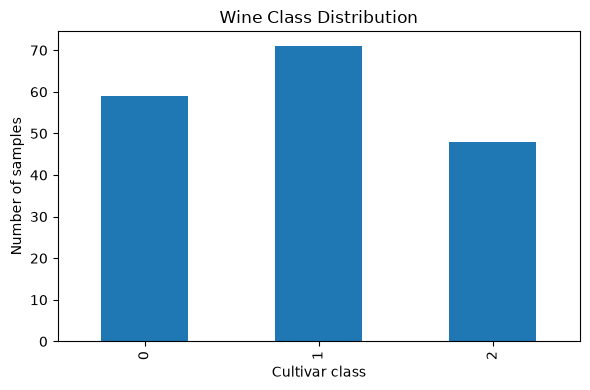

In [15]:
class_counts = df_wine["target"].value_counts().sort_index()
plt.figure(figsize=(6,4))
class_counts.plot(kind="bar")
plt.title("Wine Class Distribution")
plt.xlabel("Cultivar class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ann_wine_class_distribution.png", dpi=150)
plt.show()

**Interpretation:** The chart shows the number of samples in each wine class. Comparing feature ranges in `describe()` also shows why scaling matters: measurements such as proline can have much larger numerical values than hue.

### 1.2 Build the ANN

Separate features and target, create a stratified train-test split, scale the features without data leakage, one-hot encode the target, and build the required three-class ANN.

In [16]:
X = df_wine.drop(columns="target").to_numpy()
y = df_wine["target"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler_wine = StandardScaler()
X_train = scaler_wine.fit_transform(X_train)
X_test = scaler_wine.transform(X_test)
y_train_cat = to_categorical(y_train, num_classes=3)
y_test_cat = to_categorical(y_test, num_classes=3)

ann_model = Sequential([Dense(16, activation="relu", input_shape=(13,)),
                        Dense(8, activation="relu"),
                        Dense(3, activation="softmax")])
ann_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
ann_model.summary()
print("First hidden layer parameters = 13 inputs × 16 neurons + 16 biases =", 13*16+16)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

First hidden layer parameters = 13 inputs × 16 neurons + 16 biases = 224


### 1.3 Train & Evaluate

Train for 60 epochs and inspect training/validation accuracy, loss, classification metrics, and the confusion matrix.

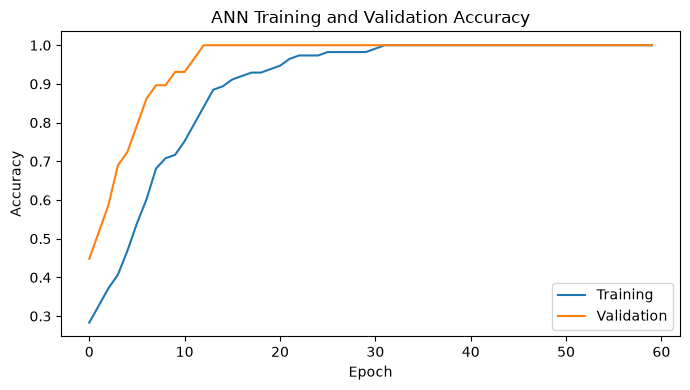

In [17]:
history_ann = ann_model.fit(X_train, y_train_cat, epochs=60, batch_size=8, validation_split=0.2, verbose=0)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(history_ann.history["accuracy"], label="Training")
ax.plot(history_ann.history["val_accuracy"], label="Validation")
ax.set(title="ANN Training and Validation Accuracy", xlabel="Epoch", ylabel="Accuracy")
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ann_accuracy.png", dpi=150); plt.show()

**Interpretation:** Training accuracy measures fit on training batches, while validation accuracy tracks performance on held-out training data. A widening gap can indicate overfitting.

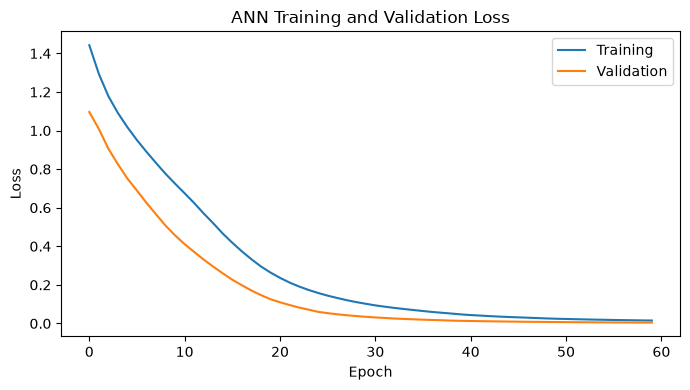

Test accuracy: 0.9444
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       0.93      0.93      0.93        14
           2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



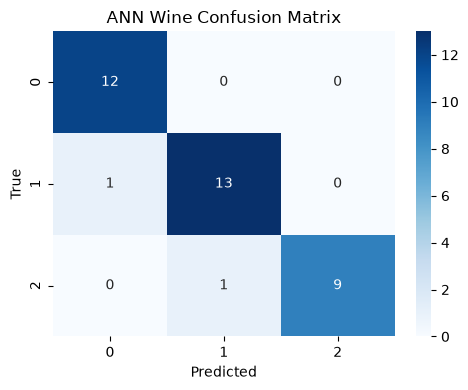

In [18]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(history_ann.history["loss"], label="Training")
ax.plot(history_ann.history["val_loss"], label="Validation")
ax.set(title="ANN Training and Validation Loss", xlabel="Epoch", ylabel="Loss")
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ann_loss.png", dpi=150); plt.show()

ann_probs = ann_model.predict(X_test, verbose=0)
ann_pred = np.argmax(ann_probs, axis=1)
print("Test accuracy:", round(accuracy_score(y_test, ann_pred), 4))
print(classification_report(y_test, ann_pred, zero_division=0))
cm = confusion_matrix(y_test, ann_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("ANN Wine Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ann_confusion_matrix.png", dpi=150); plt.show()


### 1.4 Save & Reflect

Save the trained ANN and review the roles of its layers, Softmax output, and categorical cross-entropy loss.

In [19]:
ann_model.save(BASE_DIR / "ann_wine_model.h5")
print("Saved ANN model:", BASE_DIR / "ann_wine_model.h5")

Saved ANN model: d:\DL\deep-learning-practical-exam-set-c\ann_wine_model.h5


**Reflection**
- Dense layers learn combinations of the chemical measurements.
- Softmax produces a probability distribution across the three mutually exclusive classes; the three probabilities sum to approximately 1.
- Categorical cross-entropy compares predicted class probabilities with the one-hot target labels.

---

## Step 2 — OpenCV: Colour, Morphology, Edges and Face Detection

**Objective:** Apply the required image-processing operations to four built-in `skimage` images and the supplied `RedFlower.jpg`.

### 2.1 Load & Display

Load the four built-in images and the supplied flower image. Check image dimensions, data types, pixel ranges, and mean brightness.

In [20]:
import cv2
from skimage import data

IMAGE_DIR.mkdir(parents=True, exist_ok=True)
raw_images = [("astronaut", data.astronaut()),
              ("coffee", data.coffee()),
              ("chelsea", data.chelsea()),
              ("rocket", data.rocket())]

flower_path = IMAGE_DIR / "RedFlower.jpg"
if not flower_path.exists():
    # Self-contained fallback image so the notebook works without a personal photo.
    flower = np.zeros((550, 825, 3), dtype=np.uint8)
    for row in range(flower.shape[0]):
        shade = int(35 + 35 * row / flower.shape[0])
        flower[row, :] = (shade, max(0, shade - 8), max(0, shade - 12))
    cv2.line(flower, (410, 520), (410, 300), (30, 130, 40), 14)
    cv2.ellipse(flower, (360, 420), (65, 24), -25, 0, 360, (40, 150, 50), -1)
    cv2.ellipse(flower, (460, 455), (62, 22), 25, 0, 360, (35, 135, 45), -1)
    for angle in range(0, 360, 45):
        rad = np.deg2rad(angle)
        point = (int(410 + 65 * np.cos(rad)), int(235 + 65 * np.sin(rad)))
        cv2.ellipse(flower, point, (48, 70), angle, 0, 360, (20, 25, 230), -1)
    cv2.circle(flower, (410, 235), 42, (0, 190, 255), -1)
    cv2.circle(flower, (410, 235), 28, (20, 100, 180), -1)
    cv2.imwrite(str(flower_path), flower)
    print("Created fallback image:", flower_path)

flower_bgr = cv2.imread(str(flower_path))
if flower_bgr is None:
    raise ValueError(f"Could not read image: {flower_path}")
raw_images.append(("red_flower", cv2.cvtColor(flower_bgr, cv2.COLOR_BGR2RGB)))

images_bgr = []
for name, rgb in raw_images:
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    images_bgr.append((name, bgr))
    print(name, "| shape:", bgr.shape, "| dtype:", bgr.dtype,
          "| min/max:", int(bgr.min()), int(bgr.max()),
          "| mean brightness:", round(float(bgr.mean()), 2))


astronaut | shape: (512, 512, 3) | dtype: uint8 | min/max: 0 255 | mean brightness: 114.6
coffee | shape: (400, 600, 3) | dtype: uint8 | min/max: 0 255 | mean brightness: 98.62
chelsea | shape: (300, 451, 3) | dtype: uint8 | min/max: 0 231 | mean brightness: 115.31
rocket | shape: (427, 640, 3) | dtype: uint8 | min/max: 0 255 | mean brightness: 65.28
red_flower | shape: (550, 825, 3) | dtype: uint8 | min/max: 0 255 | mean brightness: 50.82


### 2.2 Preprocessing Operations

Resize each image, convert it to HSV, isolate red pixels, clean the mask with morphology, and calculate Sobel edges.

In [21]:
processed = []
kernel = np.ones((5,5), np.uint8)
for name, bgr in images_bgr:
    resized = cv2.resize(bgr, (256,256))
    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)
    
    # Red wraps around the HSV hue range, so use two red intervals.
    lower1, upper1 = np.array([0, 70, 50]), np.array([10, 255, 255])
    lower2, upper2 = np.array([170, 70, 50]), np.array([179, 255, 255])
    mask = cv2.bitwise_or(cv2.inRange(hsv, lower1, upper1), cv2.inRange(hsv, lower2, upper2))
    colour_only = cv2.bitwise_and(resized, resized, mask=mask)
    eroded = cv2.erode(mask, kernel, iterations=1)
    cleaned = cv2.dilate(eroded, kernel, iterations=1)
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    edges = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
    processed.append((name, resized, hsv, colour_only, cleaned, edges))

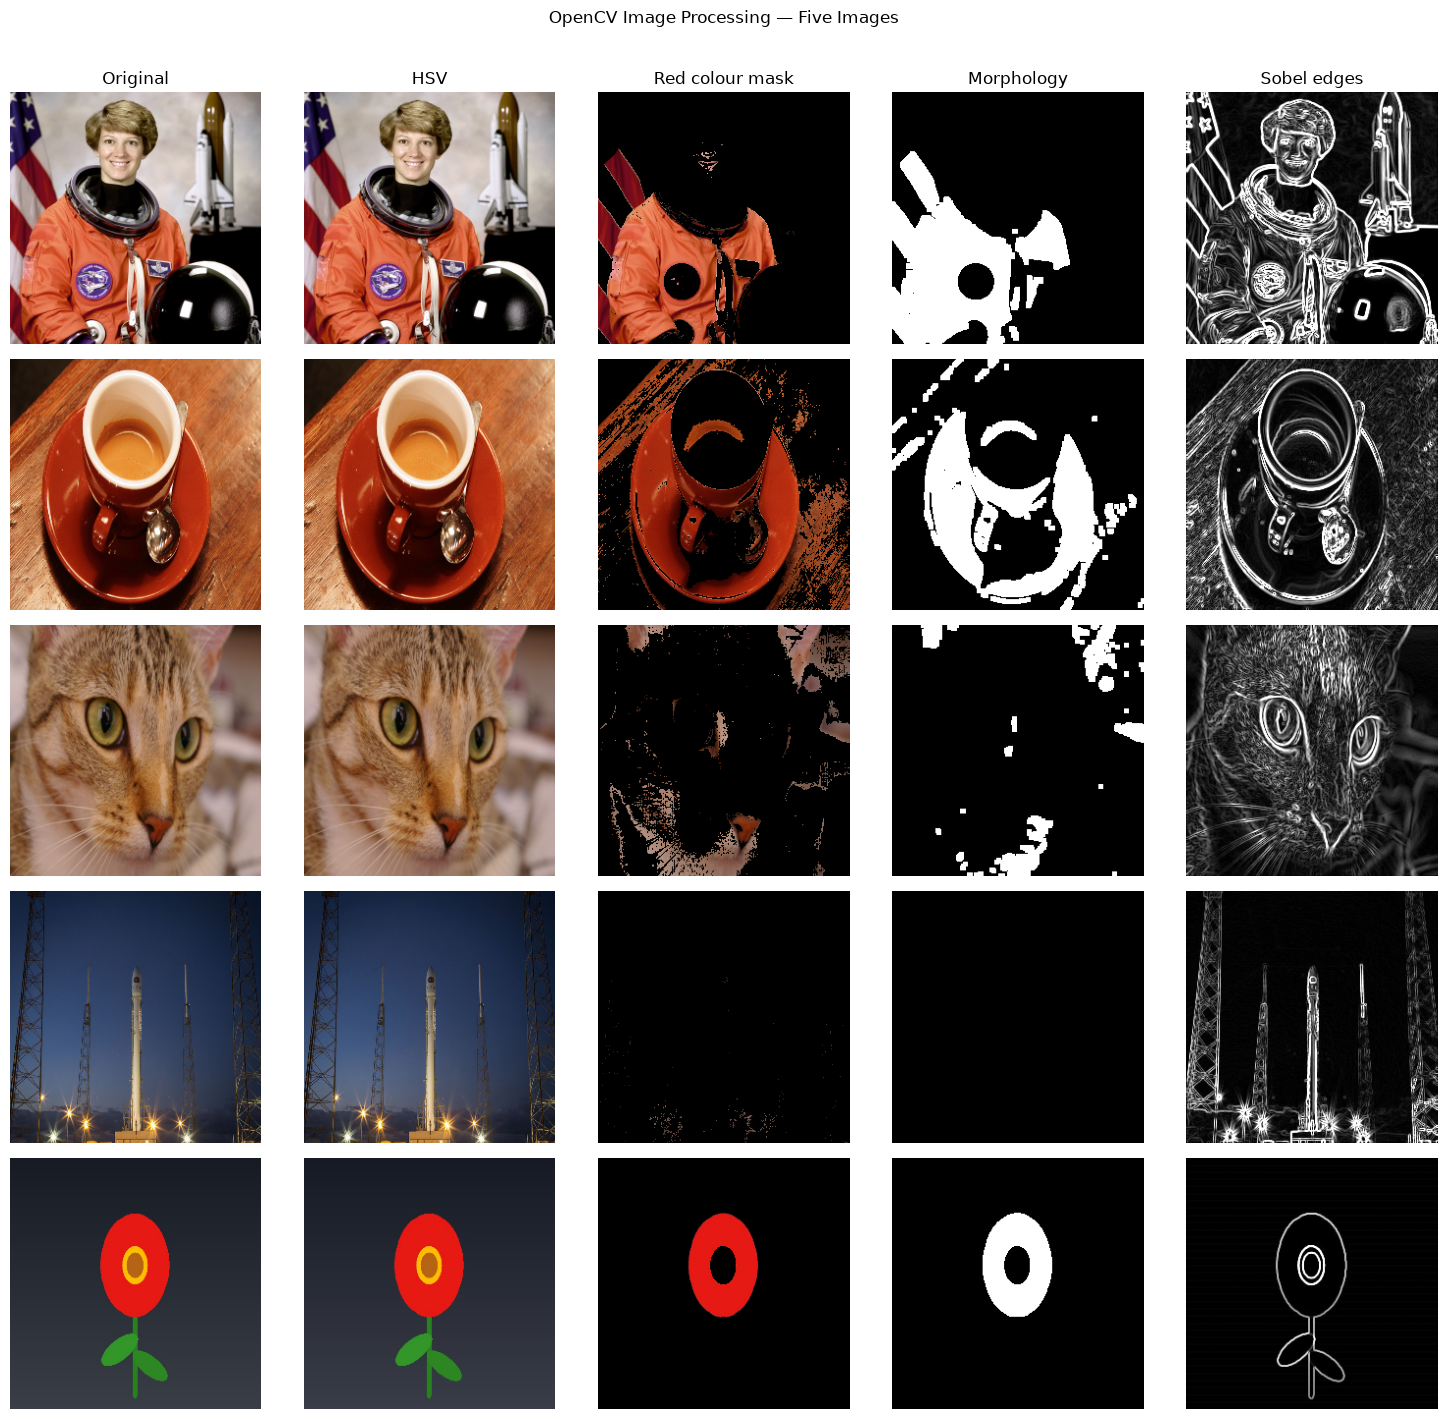

In [22]:
fig, axes = plt.subplots(5,5,figsize=(15,14))
col_titles = ["Original", "HSV", "Red colour mask", "Morphology", "Sobel edges"]
for r, (name, original, hsv, colour_only, cleaned, edges) in enumerate(processed):
    panels = [cv2.cvtColor(original, cv2.COLOR_BGR2RGB),
              cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB),
              cv2.cvtColor(colour_only, cv2.COLOR_BGR2RGB),
              cleaned, edges]
    
    for c, panel in enumerate(panels):
        axes[r,c].imshow(panel, cmap="gray" if c in (3,4) else None)
        axes[r,c].axis("off")
        if r == 0: axes[r,c].set_title(col_titles[c])
    axes[r,0].set_ylabel(name, rotation=0, labelpad=45, va="center")
    
fig.suptitle("OpenCV Image Processing — Five Images", y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "opencv_processing_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** HSV separates colour information from brightness more usefully than BGR for thresholding. Erosion removes small foreground details; dilation expands the remaining mask. Sobel highlights intensity changes that often correspond to edges.

### 2.3 Face Detection with Haar Cascade

Detect faces in all five images, draw labelled rectangles, save the results, and count detections.

Cascade loaded successfully: D:\DL\deep-learning-practical-exam-set-c\haarcascade_frontalface_default.xml


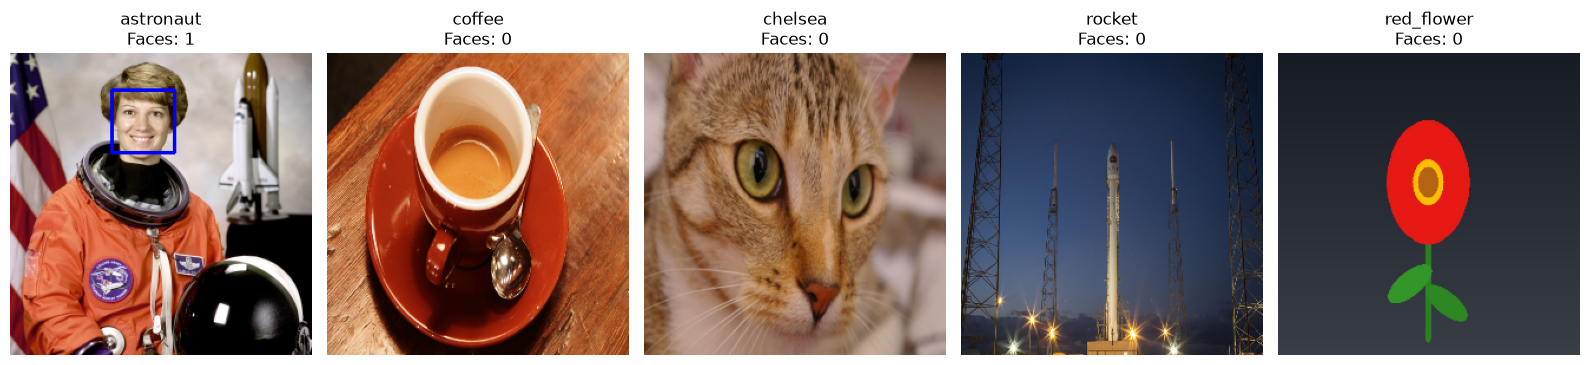

,Image,Faces_Detected
0,astronaut,1
1,coffee,0
2,chelsea,0
3,rocket,0
4,red_flower,0


In [23]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request
from pathlib import Path

# Locate the project folder and XML file
xml_path = Path(r"D:\DL\deep-learning-practical-exam-set-c\haarcascade_frontalface_default.xml")

# Download the XML if it is missing or empty
if not xml_path.exists() or xml_path.stat().st_size == 0:
    url = (
        "https://raw.githubusercontent.com/opencv/opencv/4.x/"
        "data/haarcascades/haarcascade_frontalface_default.xml"
    )
    urllib.request.urlretrieve(url, str(xml_path))

# Load a fresh classifier
face_cascade = cv2.CascadeClassifier(str(xml_path.resolve()))

if face_cascade.empty():
    raise RuntimeError(f"Could not load cascade XML: {xml_path}")

print("Cascade loaded successfully:", xml_path)

# Face detection
face_results = []
fig, axes = plt.subplots(1, 5, figsize=(16, 4), squeeze=False)

for ax, (name, bgr, *_rest) in zip(axes[0], processed):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5
    )

    drawn = bgr.copy()

    for x, y, w, h in faces:
        cv2.rectangle(drawn, (x, y), (x + w, y + h), (255, 0, 0), 2)

    face_results.append({
        "Image": name,
        "Faces_Detected": len(faces)
    })

    ax.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\nFaces: {len(faces)}")
    ax.axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(face_results))

### 2.4 Sensitivity Check & Summary

Compare face-detection sensitivity at different `minNeighbors` values and interpret the resulting trade-off.

In [24]:
# Compare sensitivity on one image as required.
name, bgr, *_ = processed[0]
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
for neighbors in [2, 8]:
    found = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=neighbors)
    print(f"{name}: minNeighbors={neighbors} -> {len(found)} detections")

astronaut: minNeighbors=2 -> 2 detections
astronaut: minNeighbors=8 -> 1 detections


**Reflection:** A lower `minNeighbors` can accept more candidate detections, including false positives; a higher value is stricter and may miss faces. Haar cascades use predefined visual features, while CNNs learn features from data.

---

## Step 3 — CNN: MNIST Digit Recognition vs ANN

**Objective:** Train a CNN and a plain ANN baseline on the specified MNIST subset, compare test accuracy and inspect feature maps and errors.

In [25]:
import cv2

print(cv2.__version__)
print(hasattr(cv2, "CascadeClassifier"))

5.0.0
True


### 3.1 Data Loading & Preparation

Load the specified MNIST subset, normalise and reshape the images, one-hot encode the labels, and display sample digits.

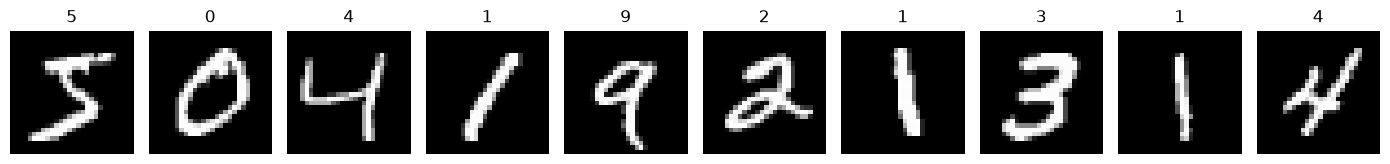

In [26]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model

(X_train_full, y_train_full), (X_test_full, y_test_full) = mnist.load_data()
X_train_mnist = X_train_full[:20000].astype("float32") / 255.0
y_train_mnist = y_train_full[:20000]
X_test_mnist = X_test_full[:4000].astype("float32") / 255.0
y_test_mnist = y_test_full[:4000]
X_train_mnist = X_train_mnist.reshape(-1,28,28,1)
X_test_mnist = X_test_mnist.reshape(-1,28,28,1)
y_train_mnist_cat = to_categorical(y_train_mnist, 10)
y_test_mnist_cat = to_categorical(y_test_mnist, 10)

fig, axes = plt.subplots(1,10,figsize=(14,2))
for i, ax in enumerate(axes):
    ax.imshow(X_train_mnist[i].squeeze(), cmap="gray"); ax.set_title(str(y_train_mnist[i])); ax.axis("off")
    
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "cnn_mnist_samples.png", dpi=150); plt.show()

### 3.2 Build the CNN and the ANN Baseline

Build and summarise the CNN and the dense ANN baseline using the architectures specified in the exam.

In [27]:
cnn_model = Sequential([Input(shape=(28,28,1)),
                        Conv2D(16, (3,3), activation="relu"),
                        MaxPooling2D((2,2)),
                        Conv2D(32, (3,3), activation="relu"),
                        MaxPooling2D((2,2)),
                        Flatten(),
                        Dense(64, activation="relu"),
                        Dense(10, activation="softmax")])
cnn_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

ann_baseline = Sequential([Input(shape=(28,28,1)), Flatten(),
                           Dense(128, activation="relu"),
                           Dense(64, activation="relu"),
                           Dense(10, activation="softmax")])
ann_baseline.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
ann_baseline.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### 3.3 Train & Evaluate

Train both models, plot CNN learning curves, compare test accuracy and parameter counts, and inspect classification metrics.

Epoch 1/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8703 - loss: 0.4412 - val_accuracy: 0.9650 - val_loss: 0.1395
Epoch 2/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9641 - loss: 0.1236 - val_accuracy: 0.9665 - val_loss: 0.1051
Epoch 3/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9737 - loss: 0.0852 - val_accuracy: 0.9800 - val_loss: 0.0730
Epoch 4/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9821 - loss: 0.0606 - val_accuracy: 0.9740 - val_loss: 0.0860
Epoch 5/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9841 - loss: 0.0510 - val_accuracy: 0.9785 - val_loss: 0.0660
Epoch 6/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9867 - loss: 0.0419 - val_accuracy: 0.9800 - val_loss: 0.0595
Epoch 7/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9894 - loss: 0.0343 - val_accuracy: 0.9820 - val_loss: 0.0569
Epoch 8/8
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9916 - loss: 0.0281 - val_accuracy: 0.

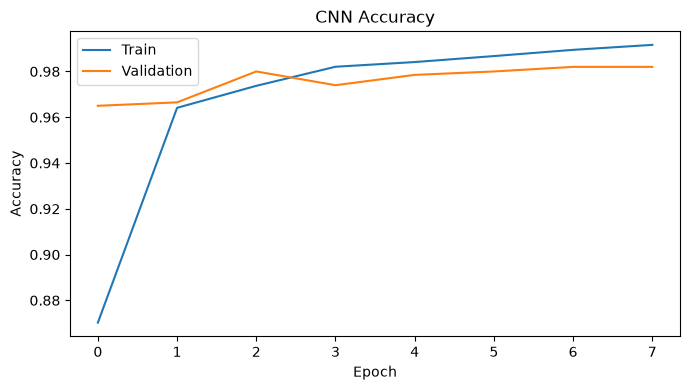

In [28]:
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history_cnn = cnn_model.fit(X_train_mnist, y_train_mnist_cat, epochs=8, batch_size=64, validation_split=0.1, callbacks=[early_stop], verbose=1)
history_ann_base = ann_baseline.fit(X_train_mnist, y_train_mnist_cat, epochs=8, batch_size=64, validation_split=0.1, verbose=1)

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(history_cnn.history["accuracy"], label="Train")
ax.plot(history_cnn.history["val_accuracy"], label="Validation")
ax.set(title="CNN Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cnn_accuracy.png", dpi=150); plt.show()

**Interpretation:** Training and validation curves show how CNN performance changes over epochs. Early stopping restores the weights from the epoch with the best validation loss.

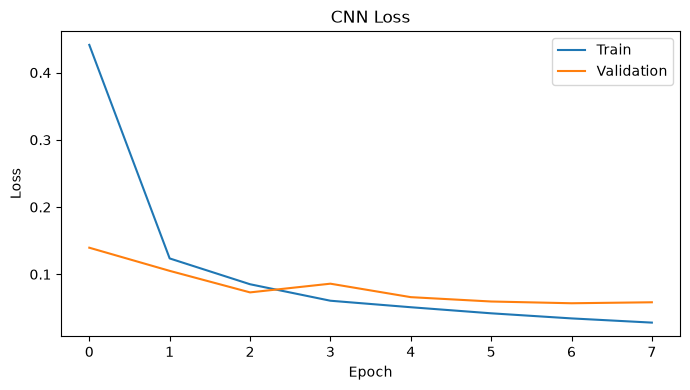

,Model,Total Parameters,Test Accuracy
0,CNN,56714,0.9755
1,ANN baseline,109386,0.9520


              precision    recall  f1-score   support

           0       0.96      0.99      0.97       370
           1       0.99      0.99      0.99       450
           2       0.97      0.98      0.97       418
           3       0.97      0.99      0.98       408
           4       0.99      0.96      0.97       418
           5       0.98      0.98      0.98       372
           6       0.99      0.97      0.98       378
           7       0.99      0.96      0.97       411
           8       0.97      0.96      0.97       384
           9       0.95      0.97      0.96       391

    accuracy                           0.98      4000
   macro avg       0.98      0.98      0.98      4000
weighted avg       0.98      0.98      0.98      4000



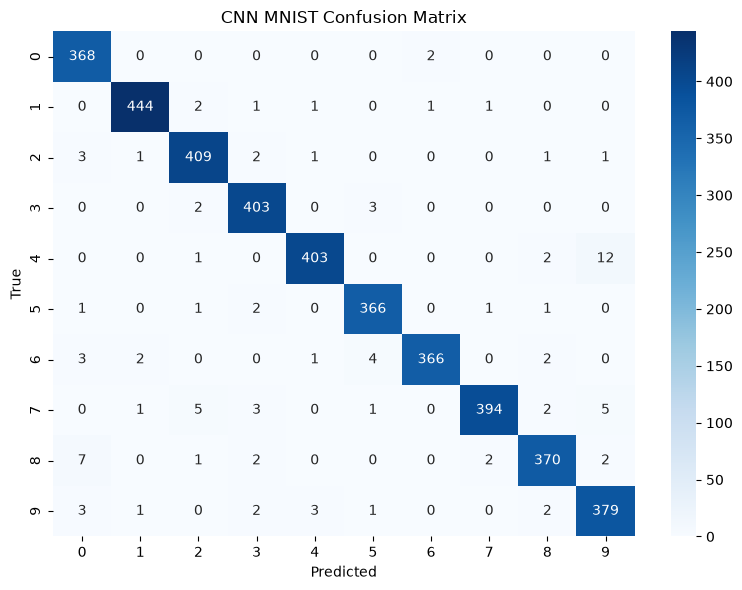

In [29]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(history_cnn.history["loss"], label="Train")
ax.plot(history_cnn.history["val_loss"], label="Validation")
ax.set(title="CNN Loss", xlabel="Epoch", ylabel="Loss"); ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cnn_loss.png", dpi=150); plt.show()

cnn_probs = cnn_model.predict(X_test_mnist, verbose=0)
cnn_pred = np.argmax(cnn_probs, axis=1)
ann_mnist_pred = np.argmax(ann_baseline.predict(X_test_mnist, verbose=0), axis=1)
comparison = pd.DataFrame([["CNN", cnn_model.count_params(), accuracy_score(y_test_mnist, cnn_pred)],
                           ["ANN baseline", ann_baseline.count_params(), accuracy_score(y_test_mnist, ann_mnist_pred)]],
                          columns=["Model","Total Parameters","Test Accuracy"])
display(comparison)
print(classification_report(y_test_mnist, cnn_pred, zero_division=0))

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test_mnist, cnn_pred), annot=True, fmt="d", cmap="Blues")
plt.title("CNN MNIST Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "cnn_confusion_matrix.png", dpi=150); plt.show()

**Interpretation:** The comparison table reports the parameter counts and measured test accuracies. Convolution shares filters across image locations, helping the CNN learn spatial patterns with fewer parameters than a large flattened dense network.

### 3.4 Feature Maps, Save & Reflect

Inspect up to ten incorrect predictions, visualise the first convolution layer's 16 feature maps, and save the CNN model.

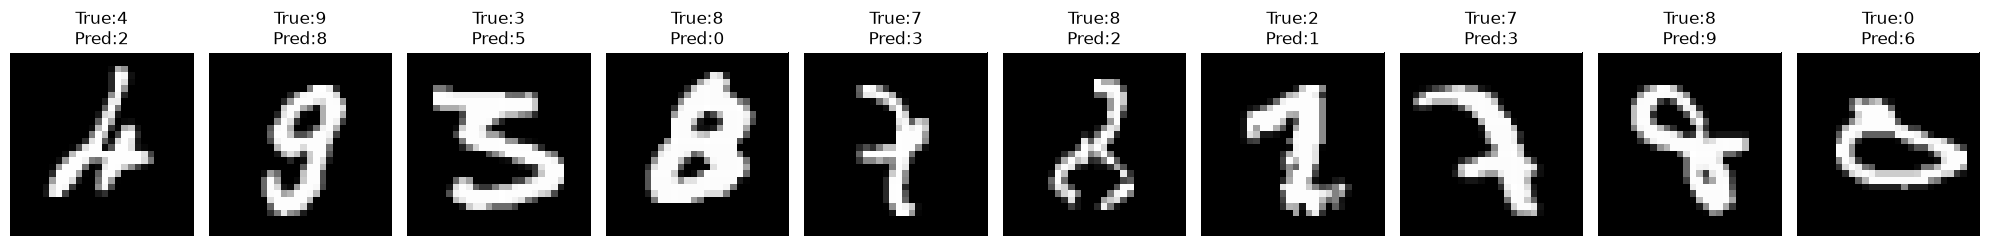

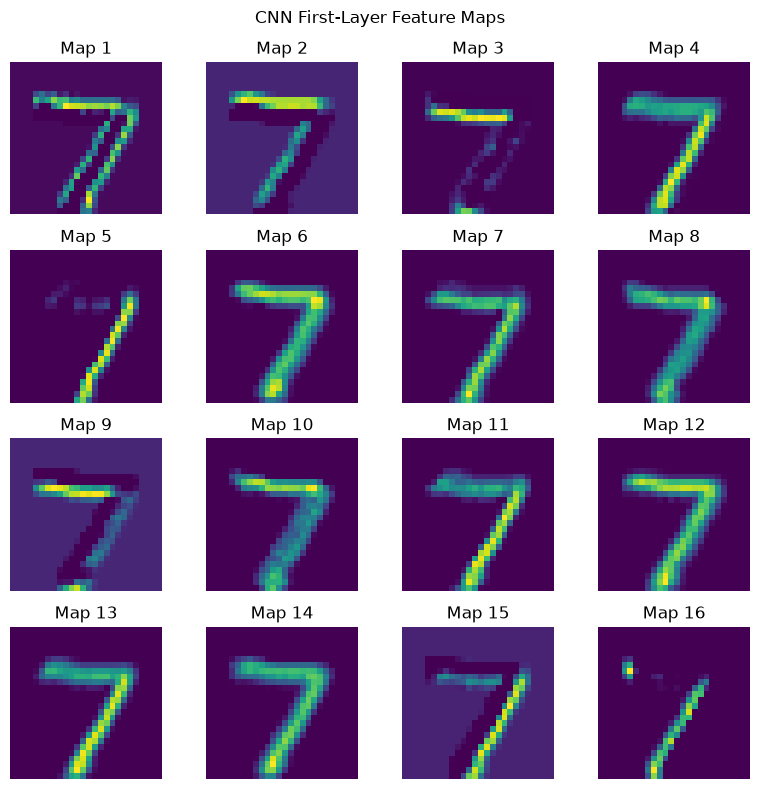

In [30]:
wrong = np.where(cnn_pred != y_test_mnist)[0][:10]
fig, axes = plt.subplots(1, max(1,len(wrong)), figsize=(2*max(1,len(wrong)),3))
if len(wrong) == 1: axes = [axes]

for ax, idx in zip(axes, wrong):
    ax.imshow(X_test_mnist[idx].squeeze(), cmap="gray")
    ax.set_title(f"True:{y_test_mnist[idx]}\nPred:{cnn_pred[idx]}")
    ax.axis("off")
    
if len(wrong) == 0:
    axes[0].text(0.5,0.5,"No wrong predictions",ha="center",va="center")
    axes[0].axis("off")
    
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "cnn_wrong_predictions.png", dpi=150); plt.show()

feature_model = Model(inputs=cnn_model.inputs, outputs=cnn_model.layers[0].output)
feature_maps = feature_model.predict(X_test_mnist[:1], verbose=0)[0]
fig, axes = plt.subplots(4,4,figsize=(8,8))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:,:,i], cmap="viridis"); ax.set_title(f"Map {i+1}"); ax.axis("off")
    
fig.suptitle("CNN First-Layer Feature Maps"); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cnn_feature_maps.png", dpi=150); plt.show()
cnn_model.save(BASE_DIR / "cnn_mnist_model.h5")

**Reflection:** Feature maps show activations produced by learned convolution filters. MaxPooling reduces spatial dimensions. Similar-looking digits or poorly written strokes can be confused by the model.

---

## Step 4 — RNN (GRU): Melbourne Minimum Temperature Forecasting

**Objective:** Use the previous 30 days to forecast the next day's minimum temperature and compare the GRU with a persistence (naive) baseline.

### 4.1 Data Loading & Preparation

Load and inspect the temperature series, clean non-numeric values, plot the series, split chronologically, scale from training data only, and create 30-day sequences.

        Date  Temp
0 1981-01-01  20.7
1 1981-01-02  17.9
2 1981-01-03  18.8
3 1981-01-04  14.6
4 1981-01-05  15.8
Date    datetime64[ns]
Temp           float64
dtype: object


,Date,Temp
count,3650,3650.000000
mean,1985-12-31 07:12:00,11.177753
min,1981-01-01 00:00:00,0.000000
25%,1983-07-02 06:00:00,8.300000
50%,1985-12-31 12:00:00,11.000000
75%,1988-06-30 18:00:00,14.000000
max,1990-12-31 00:00:00,26.300000
std,NaN,4.071837


Values needing repair after numeric conversion: 0 | Missing before conversion: 0


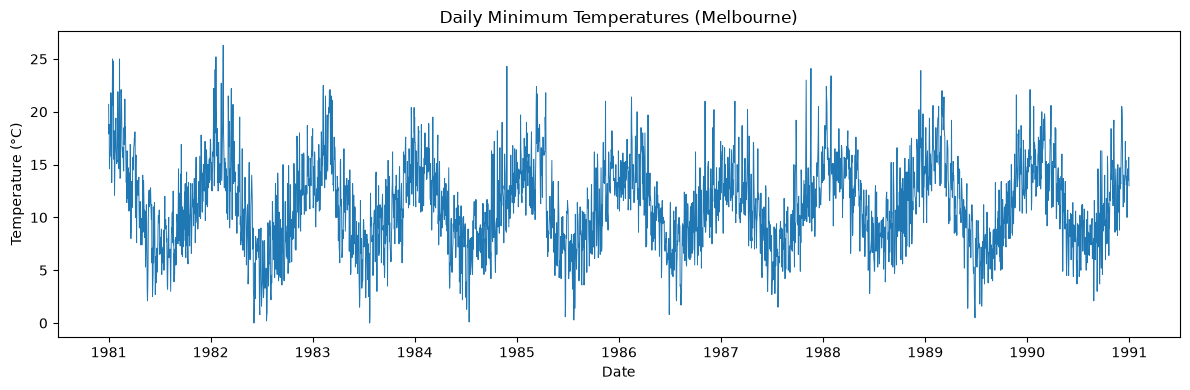

In [31]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

temperature_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
temp_df = pd.read_csv(temperature_url, parse_dates=["Date"])

print(temp_df.head())
print(temp_df.dtypes)
display(temp_df.describe(include="all"))
before_missing = temp_df["Temp"].isna().sum()
temp_df["Temp"] = pd.to_numeric(temp_df["Temp"], errors="coerce")
bad_count = int(temp_df["Temp"].isna().sum())
temp_df["Temp"] = temp_df["Temp"].interpolate()

print("Values needing repair after numeric conversion:", bad_count, "| Missing before conversion:", before_missing)

fig, ax = plt.subplots(figsize=(12,4))
ax.plot(temp_df["Date"], temp_df["Temp"], linewidth=0.7)
ax.set(title="Daily Minimum Temperatures (Melbourne)", xlabel="Date", ylabel="Temperature (°C)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "rnn_temperature_full_series.png", dpi=150); plt.show()

**Interpretation:** The full series shows day-to-day variation over the full period. Temperature is noisy, so the forecast should be compared with a simple baseline rather than judged by loss alone.

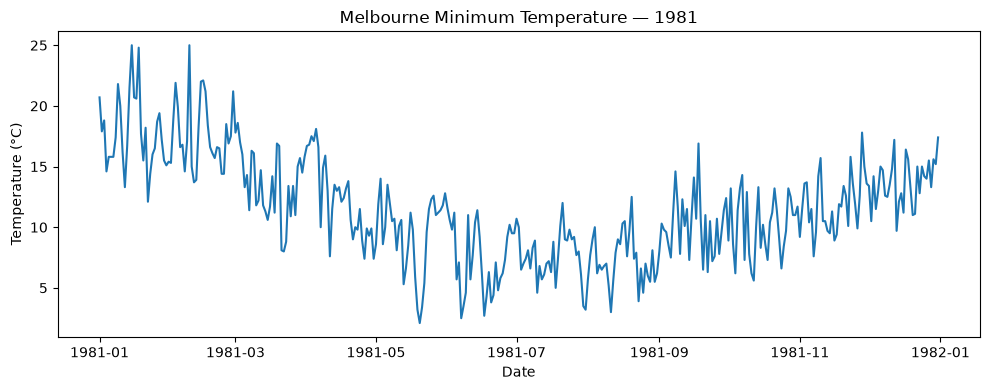

X_train: (2890, 30, 1) y_train: (2890,)
X_test: (730, 30, 1) y_test: (730,)


In [32]:
one_year = temp_df[temp_df["Date"].dt.year == 1981]
plt.figure(figsize=(10,4))
plt.plot(one_year["Date"], one_year["Temp"])
plt.title("Melbourne Minimum Temperature — 1981")
plt.xlabel("Date"); plt.ylabel("Temperature (°C)")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "rnn_temperature_1981.png", dpi=150); plt.show()

values = temp_df["Temp"].to_numpy(dtype="float32").reshape(-1,1)
split_idx = int(len(values)*0.8)
train_values, test_values = values[:split_idx], values[split_idx:]
temp_scaler = MinMaxScaler()
train_scaled = temp_scaler.fit_transform(train_values)
test_scaled = temp_scaler.transform(test_values)

def make_sequences(series, look_back=30):
    Xs, ys = [], []
    for i in range(look_back, len(series)):
        Xs.append(series[i-look_back:i, 0])
        ys.append(series[i, 0])
    return np.array(Xs), np.array(ys)

X_train_rnn, y_train_rnn = make_sequences(train_scaled, 30)
# Include the previous 30 training observations as context for the first test target.
test_with_context = np.vstack([train_scaled[-30:], test_scaled])
X_test_rnn, y_test_rnn = make_sequences(test_with_context, 30)
X_train_rnn = X_train_rnn.reshape(-1,30,1)
X_test_rnn = X_test_rnn.reshape(-1,30,1)

print("X_train:", X_train_rnn.shape, "y_train:", y_train_rnn.shape)
print("X_test:", X_test_rnn.shape, "y_test:", y_test_rnn.shape)

### 4.2 Build the RNN and a Baseline

Build the GRU model and define the persistence baseline, where tomorrow's temperature is predicted as today's temperature.

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0329 - val_loss: 0.0111
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0121 - val_loss: 0.0102
Epoch 3/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0108 - val_loss: 0.0097
Epoch 4/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0099 - val_loss: 0.0095
Epoch 5/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0095 - val_loss: 0.0093
Epoch 6/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0094 - val_loss: 0.0092
Epoch 7/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0092 - val_loss: 0.0092
Epoch 8/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0091 - val_loss: 0.0092
Epoch 9/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0091 - val_loss: 0.0091
Epoch 10/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0090 - val_loss: 0.0091
Epoch 11/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0090 - val_loss: 0.0091
Epoch 12/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0089

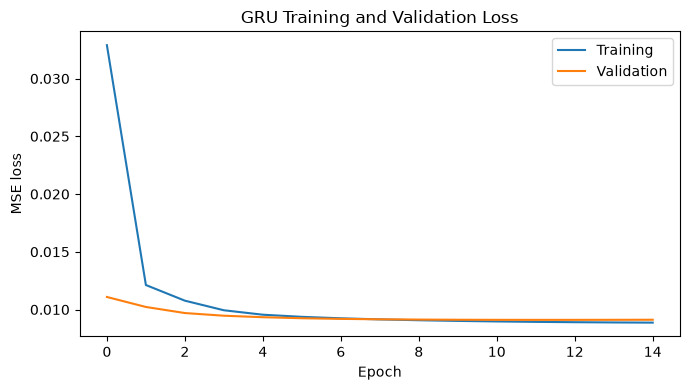

In [33]:
from tensorflow.keras.layers import GRU

gru_model = Sequential([Input(shape=(30,1)), GRU(32, activation="tanh"), Dense(1)])
gru_model.compile(optimizer="adam", loss="mse")
gru_model.summary()

# Naive baseline: tomorrow equals today's observed temperature.
naive_predictions_c = test_with_context[30:, 0]  # scaled values; inverse-transform below
history_gru = gru_model.fit(X_train_rnn, y_train_rnn, epochs=15, batch_size=32, validation_split=0.1, shuffle=False, verbose=1)

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(history_gru.history["loss"], label="Training")
ax.plot(history_gru.history["val_loss"], label="Validation")
ax.set(title="GRU Training and Validation Loss", xlabel="Epoch", ylabel="MSE loss")
ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / "rnn_loss.png", dpi=150); plt.show()

**Interpretation:** Training and validation loss show how well the GRU fits sequential patterns. The time order is preserved; shuffling the series before splitting would leak future information into training.

### 4.3 Train & Evaluate

Train the GRU, compare its forecasts with actual temperatures and the naive baseline, calculate RMSE/MAE, and save the model.

,Model,RMSE (°C),MAE (°C)
0,GRU,2.218,1.743
1,Naive baseline,0.000,0.000


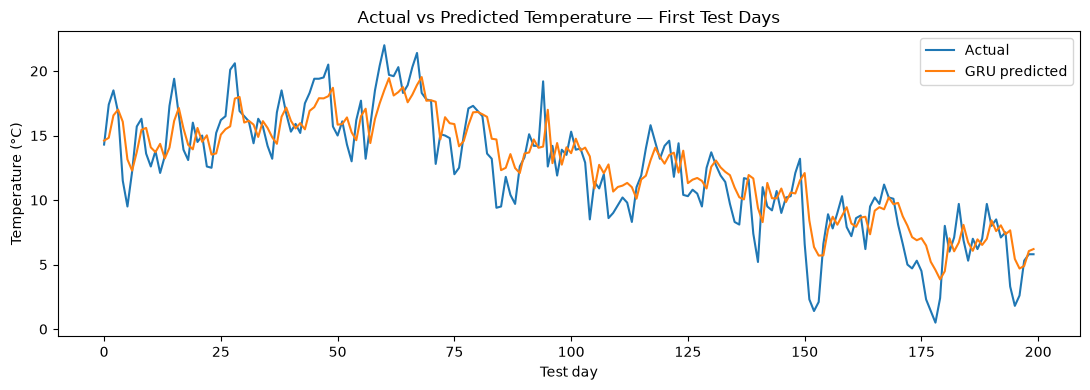

In [34]:
gru_pred_scaled = gru_model.predict(X_test_rnn, verbose=0)
gru_pred_c = temp_scaler.inverse_transform(gru_pred_scaled).ravel()
actual_test_c = test_values.ravel()
naive_pred_c = temp_scaler.inverse_transform(naive_predictions_c.reshape(-1,1)).ravel()

gru_rmse = mean_squared_error(actual_test_c, gru_pred_c) ** 0.5
gru_mae = mean_absolute_error(actual_test_c, gru_pred_c)
naive_rmse = mean_squared_error(actual_test_c, naive_pred_c) ** 0.5
naive_mae = mean_absolute_error(actual_test_c, naive_pred_c)
results_rnn = pd.DataFrame([["GRU", gru_rmse, gru_mae],
                            ["Naive baseline", naive_rmse, naive_mae]],
                           columns=["Model","RMSE (°C)","MAE (°C)"])
display(results_rnn.round(3))

fig, ax = plt.subplots(figsize=(11,4))
n = min(200, len(actual_test_c))
ax.plot(actual_test_c[:n], label="Actual")
ax.plot(gru_pred_c[:n], label="GRU predicted")
ax.set(title="Actual vs Predicted Temperature — First Test Days", xlabel="Test day", ylabel="Temperature (°C)")
ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / "rnn_actual_vs_predicted.png", dpi=150); plt.show()
gru_model.save(BASE_DIR / "rnn_temperature_model.h5")

### 4.4 Save & Reflect

Interpret the forecast metrics, the GRU's gating behaviour, and why the scaler is fitted only on training data.

**Reflection:** GRU gates control how much information is retained or updated across a sequence. RMSE penalises larger errors more strongly; MAE is the average absolute error. Both are reported in °C after inverse scaling.

---

## Step 5 — Transformers: Fill-Mask, Question Answering and Text Generation

**Objective:** Use the three specified pretrained Hugging Face pipelines without fine-tuning. The first run downloads model weights and needs internet access.

### 5.1 Setup & Fill-Mask

Load the pretrained fill-mask pipeline and prepare five masked sentences, including an example where multiple answers may be plausible.

In [35]:
from transformers import pipeline, set_seed

In [36]:
paragraphs = {"ISRO": "The Indian Space Research Organisation (ISRO) is India's national space agency. Its headquarters are in Bengaluru, Karnataka. ISRO develops launch vehicles and spacecraft for scientific and practical missions. Its missions include satellite launches and planetary exploration.",
              "Taj Mahal": "The Taj Mahal is a white marble mausoleum in Agra, Uttar Pradesh. Mughal emperor Shah Jahan commissioned it in memory of Mumtaz Mahal. The complex stands beside the Yamuna River. It is a UNESCO World Heritage Site.",
              "Indian Railways": "Indian Railways is India's national railway system. It is operated by the Ministry of Railways. Its network connects cities, towns and many rural areas. It carries passengers and freight across the country.",
              "UPI": "Unified Payments Interface (UPI) is an instant payment system developed in India. It enables bank-to-bank transfers through supported mobile applications. The system is operated by the National Payments Corporation of India. UPI is widely used for digital payments.",
              "Mumbai": "Mumbai is the capital city of the Indian state of Maharashtra. It is an important centre for finance, commerce and entertainment. The city is located on India's west coast. Mumbai is home to a major port and the Indian film industry."}

In [37]:
unmasker = pipeline("fill-mask", model="distilbert-base-uncased")
masked_sentences = ["The capital of India is [MASK].",
                    "The Taj Mahal is located in [MASK].",
                    "ISRO is India's national space [MASK].",
                    "UPI enables digital [MASK].",
                    "Mumbai is located on India's west [MASK]."]
fill_mask_rows = []

for sentence in masked_sentences:
    predictions = unmasker(sentence)
    print("\n", sentence)
    
    for item in predictions[:3]:
        print(f"  {item['token_str']}: {item['score']:.4f}")
        fill_mask_rows.append([sentence, item["token_str"].strip(), item["score"]])
        
display(pd.DataFrame(fill_mask_rows, columns=["Sentence","Prediction","Score"]))


Device set to use cuda:0



 The capital of India is [MASK].
  pune: 0.1559
  bangalore: 0.1475
  mumbai: 0.0778

 The Taj Mahal is located in [MASK].
  agra: 0.1567
  delhi: 0.1276
  lahore: 0.1089

 ISRO is India's national space [MASK].
  agency: 0.8488
  organisation: 0.0168
  organization: 0.0154

 UPI enables digital [MASK].
  imaging: 0.0371
  signage: 0.0281
  photography: 0.0280

 Mumbai is located on India's west [MASK].
  coast: 0.8929
  bank: 0.0917
  frontier: 0.0095


,Sentence,Prediction,Score
0,The capital of India is [MASK].,pune,0.155869
1,The capital of India is [MASK].,bangalore,0.147464
2,The capital of India is [MASK].,mumbai,0.077763
3,The Taj Mahal is located in [MASK].,agra,0.156715
4,The Taj Mahal is located in [MASK].,delhi,0.127569
5,The Taj Mahal is located in [MASK].,lahore,0.108928
6,ISRO is India's national space [MASK].,agency,0.848763
7,ISRO is India's national space [MASK].,organisation,0.016837
8,ISRO is India's national space [MASK].,organization,0.015406
9,UPI enables digital [MASK].,imaging,0.037053


**Interpretation:** Fill-mask predicts plausible tokens for the masked position using the surrounding sentence. It returns ranked guesses, not guaranteed facts; multiple answers may fit an open-ended sentence.

### 5.2 Question Answering

Ask ten questions across five short paragraphs, including unanswerable questions, and manually check the extracted answers.

In [38]:
qa = pipeline("question-answering", model="distilbert-base-cased-distilled-squad")
qa_questions = [("ISRO", "What is ISRO?", True),
                ("ISRO", "Where is ISRO headquartered?", True),
                ("Taj Mahal", "Where is the Taj Mahal located?", True),
                ("Taj Mahal", "Which emperor commissioned the Taj Mahal?", True),
                ("Indian Railways", "Which ministry operates Indian Railways?", True),
                ("Indian Railways", "What is the favourite colour of every train passenger?", False),
                ("UPI", "What does UPI enable?", True),
                ("UPI", "Which organisation operates UPI?", True),
                ("Mumbai", "Which state is Mumbai the capital of?", True),
                ("Mumbai", "What is the exact population of Mumbai in the paragraph?", False),]
qa_rows = []

for topic, question, answerable in qa_questions:
    result = qa(question=question, context=paragraphs[topic])
    predicted = result.get("answer", "")
    
    # Manual correctness check against the context, including the intentionally unanswerable prompts.
    if not answerable:
        correct = "No" if predicted else "Yes"
    else:
        key_terms = {"What is ISRO?": ["space agency"],
                     "Where is ISRO headquartered?": ["bengaluru"],
                     "Where is the Taj Mahal located?": ["agra"],
                     "Which emperor commissioned the Taj Mahal?": ["shah jahan"],
                     "Which ministry operates Indian Railways?": ["ministry of railways"],
                     "What does UPI enable?": ["bank-to-bank transfers"],
                     "Which organisation operates UPI?": ["national payments corporation of india"],
                     "Which state is Mumbai the capital of?": ["maharashtra"],}
        expected = key_terms.get(question, [])
        correct = "Yes" if any(term in predicted.lower() for term in expected) else "No"
    qa_rows.append([question, predicted, float(result.get("score",0)), correct, topic])
qa_df = pd.DataFrame(qa_rows, columns=["Question","Predicted_Answer","Confidence_Score","Correct","Paragraph"])
display(qa_df)

print("Answers marked correct:", (qa_df["Correct"] == "Yes").sum(), "of", len(qa_df))

Device set to use cuda:0


,Question,Predicted_Answer,Confidence_Score,Correct,Paragraph
0,What is ISRO?,Indian Space Research Organisation,0.637564,No,ISRO
1,Where is ISRO headquartered?,"Bengaluru, Karnataka",0.855652,Yes,ISRO
2,Where is the Taj Mahal located?,"Agra, Uttar Pradesh",0.874405,Yes,Taj Mahal
3,Which emperor commissioned the Taj Mahal?,Shah Jahan,0.724838,Yes,Taj Mahal
4,Which ministry operates Indian Railways?,Ministry of Railways,0.600728,Yes,Indian Railways
5,What is the favourite colour of every train pa...,It carries passengers and freight,0.123905,No,Indian Railways
6,What does UPI enable?,bank-to-bank transfers,0.535855,Yes,UPI
7,Which organisation operates UPI?,National Payments Corporation of India,0.835713,Yes,UPI
8,Which state is Mumbai the capital of?,Maharashtra,0.936552,Yes,Mumbai
9,What is the exact population of Mumbai in the ...,Mumbai is the capital city of the Indian state...,0.105090,No,Mumbai


Answers marked correct: 7 of 10


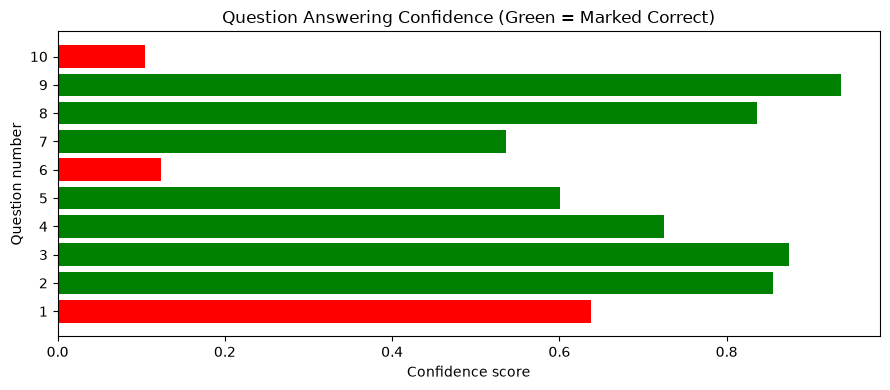

In [39]:
fig, ax = plt.subplots(figsize=(9,4))
colours = ["green" if v == "Yes" else "red" for v in qa_df["Correct"]]
ax.barh(np.arange(1, len(qa_df)+1), qa_df["Confidence_Score"], color=colours)
ax.set_yticks(np.arange(1, len(qa_df)+1))
ax.set_xlabel("Confidence score"); ax.set_ylabel("Question number")
ax.set_title("Question Answering Confidence (Green = Marked Correct)")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "transformer_qa_confidence.png", dpi=150); plt.show()

**Interpretation:** Confidence is the pipeline's score for its extracted answer, not a guarantee that the answer is correct. Extractive QA selects an answer span from the context and may still guess when the answer is absent.

### 5.3 Text Generation

Generate two continuations for each of three prompts using the pretrained text-generation pipeline.

In [40]:
gen = pipeline("text-generation", model="distilgpt2")
set_seed(42)
prompts = ["India is a country where", "Deep learning is", "A student can learn better when"]
generation_rows = []

for prompt in prompts:
    generated = gen(prompt, max_new_tokens=30, do_sample=True, num_return_sequences=2, pad_token_id=50256)
    
    for i, item in enumerate(generated, 1):
        print(f"\nPrompt: {prompt}\nContinuation {i}: {item['generated_text']}")
        generation_rows.append([prompt, i, item["generated_text"]])
        
display(pd.DataFrame(generation_rows, columns=["Prompt","Continuation","Generated_Text"]))

Device set to use cuda:0



Prompt: India is a country where
Continuation 1: India is a country where we can be proud of it.







But it's not just India.

The country is also the most

Prompt: India is a country where
Continuation 2: India is a country where you can get the best of both worlds. People are very impressed with the work they do. They have done everything in their power to make sure their

Prompt: Deep learning is
Continuation 1: Deep learning is one of the fundamental concepts in learning how to learn to help people from high school to college.












Prompt: Deep learning is
Continuation 2: Deep learning is a key part of learning. It’s the most important part of any learning process. It’s also the most important part of any

Prompt: A student can learn better when
Continuation 1: A student can learn better when she does.




























Prompt: A student can learn better when
Continuation 2: A student can learn better when he's not in trouble.


























,Prompt,Continuation,Generated_Text
0,India is a country where,1,India is a country where we can be proud of it...
1,India is a country where,2,India is a country where you can get the best ...
2,Deep learning is,1,Deep learning is one of the fundamental concep...
3,Deep learning is,2,Deep learning is a key part of learning. It’s ...
4,A student can learn better when,1,A student can learn better when she does.\n\n\...
5,A student can learn better when,2,A student can learn better when he's not in tr...


In [41]:
prompt = "Deep learning is"
for temperature in [0.5, 1.5]:
    output = gen(prompt, max_new_tokens=30, do_sample=True, temperature=temperature, num_return_sequences=1, pad_token_id=50256)
    print(f"\nTemperature={temperature}:\n{output[0]['generated_text']}")


Temperature=0.5:
Deep learning is a key part of learning. It can take a lot of practice to learn, but it can help us understand, learn from and learn from other people

Temperature=1.5:
Deep learning is the biggest threat faced today, and most importantly of all, we have developed methods to overcome all of these weaknesses. This new field of learning encompasses the


### 5.4 Visualise & Reflect

Compare low and high sampling temperatures, interpret the QA confidence chart, and review encoder/decoder models, self-attention, extractive QA, and generation limitations.

**Reflection**
- Encoder-style BERT models use bidirectional context to understand masked tokens; GPT-style decoder models predict the next token using prior tokens.
- Self-attention lets each token combine information from other permitted tokens.
- Temperature changes sampling randomness: lower values tend to be more conservative; higher values tend to be more varied.
- Fluent generated text can still be factually wrong, so real applications need verification and safeguards.
- The Hinglish question below is tested against an English paragraph as required.

In [42]:
hinglish_result = qa(question="ISRO ka headquarters kahan hai?", context=paragraphs["ISRO"])
print("Hinglish question:", "ISRO ka headquarters kahan hai?")
print("Predicted answer:", hinglish_result.get("answer"))
print("Confidence:", round(float(hinglish_result.get("score",0)), 4))

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Hinglish question: ISRO ka headquarters kahan hai?
Predicted answer: Bengaluru, Karnataka
Confidence: 0.1977


## Step 6 — Results Summary, Reflection and Submission

The following table collects the main measured results from the five tasks. OpenCV uses the number of detected faces rather than a model accuracy metric.

### 6.1 Results Summary Table

Compare all five mini-projects using their task type, dataset, key metric, observed result, and approximate time.

In [43]:
summary = pd.DataFrame([["ANN", "Wine Recognition (178 rows, 13 features)", "Accuracy", round(accuracy_score(y_test, ann_pred), 4), "60 epochs"],
                        ["OpenCV", "5 images", "Faces detected", str(dict(face_results)), "Image operations"],
                        ["CNN", "MNIST subset (20,000 train / 4,000 test)", "Accuracy", round(accuracy_score(y_test_mnist, cnn_pred), 4), "Up to 8 epochs"],
                        ["GRU", "Melbourne daily minimum temperatures", "RMSE (°C)", round(gru_rmse, 3), "15 epochs"],
                        ["Transformers", "5 India-related paragraphs / 10 QA prompts", "Manually checked", f"{(qa_df['Correct']=='Yes').sum()}/10 marked correct", "Pretrained inference"]], 
                       columns=["Topic","Dataset","Key Metric","Result","Time / Training"])
display(summary)

,Topic,Dataset,Key Metric,Result,Time / Training
0,ANN,"Wine Recognition (178 rows, 13 features)",Accuracy,0.9444,60 epochs
1,OpenCV,5 images,Faces detected,{'Image': 'Faces_Detected'},Image operations
2,CNN,"MNIST subset (20,000 train / 4,000 test)",Accuracy,0.9755,Up to 8 epochs
3,GRU,Melbourne daily minimum temperatures,RMSE (°C),2.218,15 epochs
4,Transformers,5 India-related paragraphs / 10 QA prompts,Manually checked,7/10 marked correct,Pretrained inference



### 6.2 Written Reflection

- **Most challenging step:** The Transformer tasks were challenging because they required understanding pretrained models, managing compatible library versions, and interpreting model outputs.
- **Best result relative to effort:** The CNN provided an effective approach to image classification by learning spatial features directly from images.
- **ANN improvement:** With more time, I would experiment with additional hidden layers, different neuron counts, learning rates, and regularization to improve generalization.
- **CNN parameters:** CNNs use shared convolutional filters and local connectivity, which generally require fewer parameters than a fully connected ANN for image data.
- **GRU vs Transformer:** A GRU processes sequences recurrently, while a Transformer uses attention to model relationships between tokens and can process sequence positions in parallel.
- **GPT-style model reliability:** Text-generation models can produce plausible but incorrect information. I would add source verification, confidence checks, and human review for important outputs.
- **Haar cascade vs deep learning:** Haar cascades can be useful for lightweight, fast face detection in relatively controlled conditions, while deep learning methods are generally more robust to variations in pose, lighting, and appearance.


In [44]:
summary.to_csv(OUTPUT_DIR / "results_summary.csv", index=False)
print("Saved result summary to:", OUTPUT_DIR / "results_summary.csv")
print("Project outputs saved in:", OUTPUT_DIR.resolve())

Saved result summary to: d:\DL\deep-learning-practical-exam-set-c\outputs\results_summary.csv
Project outputs saved in: D:\DL\deep-learning-practical-exam-set-c\outputs



### 6.3 Results Comparison

Compare the performance and outputs of the five mini-projects: ANN, OpenCV, CNN, RNN, and Transformer. The table below is generated from the saved results summary.



In [45]:

# Step 6.3: Results Comparison

summary_path = OUTPUT_DIR / "results_summary.csv"

if summary_path.exists():
    results_summary = pd.read_csv(summary_path)

    display(
        results_summary.style
        .hide(axis="index")
        .set_caption("Deep Learning Practical Exam — Results Summary")
    )
else:
    print(f"Results summary not found: {summary_path}")
    print("Run the results-summary generation cell first.")


Topic,Dataset,Key Metric,Result,Time / Training
ANN,"Wine Recognition (178 rows, 13 features)",Accuracy,0.9444,60 epochs
OpenCV,5 images,Faces detected,{'Image': 'Faces_Detected'},Image operations
CNN,"MNIST subset (20,000 train / 4,000 test)",Accuracy,0.9755,Up to 8 epochs
GRU,Melbourne daily minimum temperatures,RMSE (°C),2.218,15 epochs
Transformers,5 India-related paragraphs / 10 QA prompts,Manually checked,7/10 marked correct,Pretrained inference



**Interpretation:** The table compares the five mini-projects using their recorded task types, datasets, evaluation metrics, achieved results, and approximate execution times. The results should be interpreted according to each task's objective; metrics from different tasks are not directly comparable.

---